# De la alarma al diagnóstico

## El Agente 1, un expediente objetivo, un diagnóstico de ingeniero y su evaluación

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de
Fin de Máster. Séptimo de los ocho notebooks y primero de los dos de agentes.*

## Resumen

Un detector entrega un número, y un operador necesita dos cosas más, qué está pasando y si merece
la pena actuar. El Agente 1 cubre ese salto en tres pasos, todos **sin ver la etiqueta** de fallo
(*label-free*), que es la condición necesaria para que la evaluación sea válida, porque la etiqueta
entra al final y únicamente en la métrica.

Primero compila un **expediente objetivo** con el margen sobre el umbral, el canal disparador, el
contrafactual acumulado, que dice qué canales sostienen el *score*, y los gradientes integrados, que
dicen si la desviación es local o **relacional**. Todo se computa con las mismas primitivas de
explicabilidad verificadas en los notebooks 1 a 3, y reproduce sus dos casos canónicos. C ev11 sale
**relacional**, porque el sensor no se desvía en absoluto, con una atribución propia del 2 %, pero
la turbina deja de predecirlo, y C ev66 sale **canal único**, porque un solo sensor explica el 93 %
del *score*, con una atribución propia del 81 %.

Segundo, una **taxonomía calibrada** convierte el expediente en un tipo de precursor y una
categorización, *escalar*, *vigilar* o *descartar*. Como en el Agente 2, **las reglas deciden y el
modelo de lenguaje solo narra**, es decir, redacta la hipótesis citando números ya calculados, pero
no clasifica ni puntúa. Un experimento de control lo respalda, porque dejado decidir, el modelo
local sobre-escala sistemáticamente los casos ambiguos, así que el número que declara el trabajo es
siempre el del mecanismo determinista.

Tercero, se **evalúa** si esa categorización mejora el CARE, suprimiendo alarmas según el triaje y
recalculando la métrica oficial. El resultado es el núcleo del notebook. A una semilla, la variante
estricta sube el CARE del parque B de 0.7014 a 0.7318, pero a **cinco semillas ese efecto se
desvanece** (0.6508 ± 0.069, positivo en 2 de 5), de modo que era **suerte de semilla**. La
conclusión no es un fracaso sino un replanteamiento, porque el valor del Agente 1 no está en mejorar
la métrica sino en ser una **capa de decisión interpretable**, y su salida fiable, `escalar`, es la
que alimenta la planificación del notebook 6.

## 0. Preparación y verificación

Se cargan las primitivas de diagnóstico, la evidencia *label-free* y el clasificador de precursor, y
se verifica que reproducen los dos casos canónicos de los notebooks de explicabilidad, la deriva
**relacional** de C ev11, con atribución propia por debajo del 10 %, y el fallo de **canal único**
de C ev66, con atribución propia por encima del 80 %.

In [1]:
# Preparacion del entorno comun a los 4 notebooks XAI
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (str(ROOT), str(ROOT / "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
warnings.filterwarnings("ignore")

# ipykernel OutStream no tiene .buffer: evita que el guard utf-8 de los scripts del repo
# (if sys.stdout.encoding != "utf-8": sys.stdout = io.TextIOWrapper(sys.stdout.buffer, ...))
# intente envolverlo al importarlos.
for _s in (sys.stdout, sys.stderr):
    try:
        if getattr(_s, "encoding", None) != "utf-8":
            _s.encoding = "utf-8"
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.xai import (load_ae, load_ae_events, load_meta, load_scores, load_trajdev,
                     load_trajdev_events, trajdev_channel_z)
from src.xai.loaders import DEVICE, ae_scores, trajdev_forecast_errors, trajdev_score
from src.xai.cusum import cusum_series, first_alarm, h_sweep_best, official_cusum
from src.xai import plots as xp
from src.xai.attrib import (ae_integrated_gradients, ae_residual_sensor, occlusion_per_channel,
                            residual_train_stats, trajdev_counterfactual,
                            trajdev_integrated_gradients)
from src.care_official.adapter import OfficialCAREAdapter

xp.set_style()
np.random.seed(42); torch.manual_seed(42)
print(f"ROOT: {ROOT}")
print(f"dispositivo: {DEVICE} | torch {torch.__version__}")

ROOT: .
dispositivo: cuda | torch 2.10.0+cu128


In [2]:
# Los calculos pesados se cachean en results/xai_cache/nb5/
CACHE = ROOT / "results" / "xai_cache" / "nb5"
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """np.savez de dict de arrays; si existe, carga sin recomputar."""
    p = CACHE / f"{name}.npz"
    if p.exists():
        z = np.load(p, allow_pickle=True)
        return {k: z[k] for k in z.files}
    out = fn()
    np.savez_compressed(p, **out)
    return out

print(f"cache: {CACHE}")

cache: .\results\xai_cache\nb5


In [3]:
from src.agents.contracts import TriageAction
from src.agents.diagnose import DiagnoseAgent
from src.agents.tools.xai_tools import get_alarm_evidence, clasificar_precursor, _context

# GATE: reproducir los dos casos canonicos (label-free, bundle s42 committeado)
ev11 = get_alarm_evidence("C", 11)
ev66 = get_alarm_evidence("C", 66)
t11, _ = clasificar_precursor(ev11)
t66, _ = clasificar_precursor(ev66)
assert t11.value == "relacional" and ev11.ig_propio_pct < 10, f"ev11 no reproduce: {t11.value}, IG {ev11.ig_propio_pct}"
assert t66.value == "canal_unico" and ev66.ig_propio_pct > 80, f"ev66 no reproduce: {t66.value}, IG {ev66.ig_propio_pct}"
print(f"GATE OK — C ev11: {t11.value} (margen {ev11.margen_sh:.0f}, IG propio {ev11.ig_propio_pct}%) | "
      f"C ev66: {t66.value} (margen {ev66.margen_sh:.0f}, IG propio {ev66.ig_propio_pct}%). "
      f"Evidencia label-free reproducida desde el bundle s42.")

GATE OK — C ev11: relacional (margen 600, IG propio 2.0%) | C ev66: canal_unico (margen 101, IG propio 81.5%). Evidencia label-free reproducida desde el bundle s42.


## 1. El expediente *label-free*, de un *score* a evidencia objetiva

La alarma es el instante en que el CUSUM del error de pronóstico supera el umbral `h_base`, un
percentil del train calculado **sin mirar las etiquetas**, de modo que no hay fuga de información
del test. El expediente responde, con números verificables, qué sostiene esa alarma:

- **Margen** S/h, cuánto supera el *score* al umbral, es decir, la fuerza de la señal.
- **Contrafactual acumulado**, es decir, cuánto cae el *score* al sustituir los k canales de mayor
  *z* por su propio pronóstico. Revela si lo sostiene **un** canal o un **grupo**.
- **Gradientes integrados**, que reparten la atribución entre el canal propio y su contexto. Si el
  canal propio pesa poco, por debajo del 10 %, el sensor **no se está desviando**, y lo que se ha
  roto es su *relación* con el resto de la turbina, una anomalía **relacional** que un detector de
  umbral no puede ver.

Los dos casos canónicos son el contraste que buscamos.

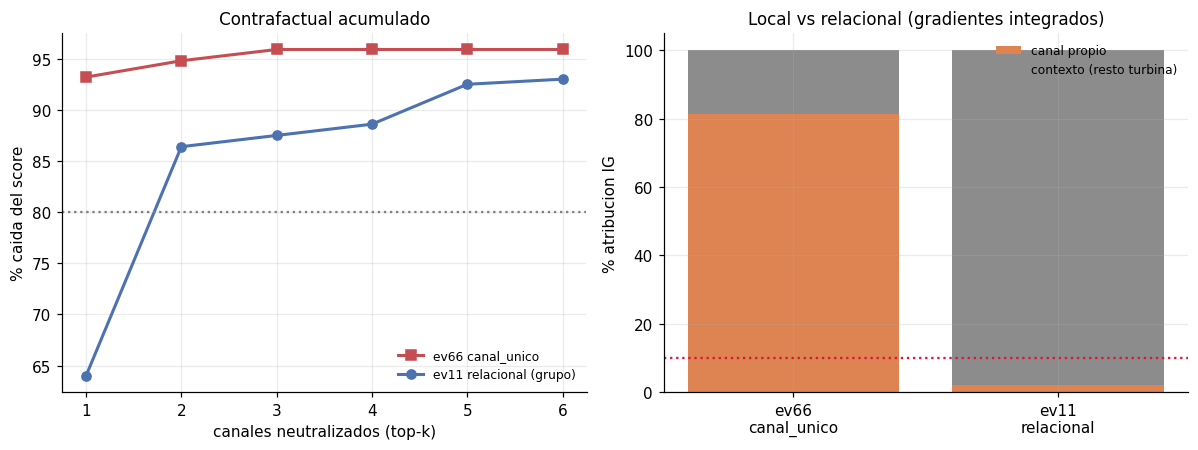

ev66 (canal_unico): 1 canal explica 93% del score, IG propio 81.5%
ev11 (relacional):  el score sube escalonado 64->93% (grupo), IG propio 2.0%


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
# (a) contrafactual acumulado: canal_unico salta al 93% con 1 canal; relacional sube escalonado
k11 = np.arange(1, len(ev11.cf_acumulado_pct) + 1)
k66 = np.arange(1, len(ev66.cf_acumulado_pct) + 1)
ax1.plot(k66, ev66.cf_acumulado_pct, "s-", color="#C44E52", lw=2, label="ev66 canal_unico")
ax1.plot(k11, ev11.cf_acumulado_pct, "o-", color="#4C72B0", lw=2, label="ev11 relacional (grupo)")
ax1.axhline(80, ls=":", color="gray"); ax1.set_xlabel("canales neutralizados (top-k)")
ax1.set_ylabel("% caida del score"); ax1.set_title("Contrafactual acumulado"); ax1.legend(fontsize=8)
# (b) IG: canal propio vs contexto
labels = ["ev66\ncanal_unico", "ev11\nrelacional"]
propio = [ev66.ig_propio_pct, ev11.ig_propio_pct]
contexto = [100 - ev66.ig_propio_pct, 100 - ev11.ig_propio_pct]
ax2.bar(labels, propio, color="#DD8452", label="canal propio")
ax2.bar(labels, contexto, bottom=propio, color="#8C8C8C", label="contexto (resto turbina)")
ax2.axhline(10, ls=":", color="crimson"); ax2.set_ylabel("% atribucion IG")
ax2.set_title("Local vs relacional (gradientes integrados)"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"ev66 (canal_unico): 1 canal explica {ev66.cf_acumulado_pct[0]:.0f}% del score, IG propio {ev66.ig_propio_pct}%")
print(f"ev11 (relacional):  el score sube escalonado {ev11.cf_acumulado_pct[0]:.0f}->{ev11.cf_acumulado_pct[-1]:.0f}% (grupo), IG propio {ev11.ig_propio_pct}%")

## 2. El diagnóstico, reglas calibradas y un modelo de lenguaje que solo narra

La taxonomía de precursor, calibrada en los notebooks 1 a 4, asigna a cada expediente un tipo, que
puede ser *canal único*, *grupo coherente*, *difuso*, *relacional*, *mixto* o *sin señal*, y una
categorización. **La decisión la toman umbrales reproducibles, no el modelo de lenguaje.** Se
`escala` el precursor creíble y sostenido, se `descarta` la desviación transitoria de bajo margen,
y se `vigila` la banda ambigua, donde la **persistencia** de la alarma desempata, porque una alarma
sostenida es un precursor real y una transitoria es una falsa alarma.

El modelo de lenguaje local, cuando está disponible, solo redacta la hipótesis citando los números
del expediente. Si no lo está, o si su salida no valida contra el contrato, un mecanismo
determinista de reglas produce el resultado. Se diagnostican a continuación los eventos que se usan
como casos de estudio.

In [5]:
diag = DiagnoseAgent(llm=None)   # decision + hipotesis deterministas (reproducible)
CASOS = [("C", 11), ("C", 66), ("C", 15), ("B", 34), ("B", 53)]
print(f"{'evento':8} {'margen':>8} {'persist':>8} {'tipo':>16} {'triaje':>10}  hipotesis")
for farm, ev in CASOS:
    rep = diag.run(get_alarm_evidence(farm, ev))
    e = rep.evidencia
    ps = f"{e.persistencia_frac:.2f}" if e.persistencia_frac is not None else "-"
    print(f"{farm+' ev'+str(ev):8} {e.margen_sh:>8.2f} {ps:>8} {rep.tipo_precursor.value:>16} "
          f"{rep.triage.action.value:>10}  {rep.hipotesis[:70]}")

evento     margen  persist             tipo     triaje  hipotesis


C ev11     600.34     1.00       relacional    escalar  Recomendacion: escalar a planificacion: reparar DENTRO de la ventana, 
C ev66     100.74     1.00      canal_unico    escalar  Recomendacion: escalar a planificacion: reparar DENTRO de la ventana, 


C ev15       0.21        -        sin_senal  descartar  Recomendacion: descartar; no requiere accion.
Que pasa: ningun sensor 


B ev34       3.62     0.24            mixto    vigilar  Recomendacion: mantener en vigilancia y revisar en los proximos ciclos
B ev53      35.44     0.99            mixto    escalar  Recomendacion: escalar a planificacion: reparar DENTRO de la ventana, 


## 3. ¿Mejora la categorización la métrica?

La pregunta cuantitativa estaba **pre-registrada**. Si suprimimos alarmas según el triaje, ¿sube el
CARE? Se evalúa sobre los 15 eventos del parque B con el harness oficial, en dos variantes, la
**principal**, que suprime solo `descartar`, y la **estricta**, que suprime `descartar` y `vigilar`.
El triaje no ve la etiqueta, que entra solo en la métrica y en la matriz de confusión.

In [6]:
cB = _context("B", None, 42)
metaB, ev_SB, hB = cB["meta"], cB["ev_S"], cB["h"]
from src.care_official.adapter import OfficialCAREAdapter
adapterB = OfficialCAREAdapter(raw_path="data/raw/CARE_To_Compare", farm="B", window_size=27)
alarmanB = {e for e in metaB if (ev_SB[e] > hB).any()}
gtB = {e: (m["event_label"] != "anomaly") for e, m in metaB.items()}   # True=normal (solo para metrica)

triB = {e: diag.run(get_alarm_evidence("B", e)).triage.action for e in metaB}
descartar = {e for e, a in triB.items() if a is TriageAction.DESCARTAR}
vigilar = {e for e, a in triB.items() if a is TriageAction.VIGILAR}

def _care(supr):
    preds = [{"event_id": e, "asset_id": m["asset_id"], "event_label": m["event_label"],
              "window_timestamps": m["window_timestamps"],
              "window_predictions": (np.zeros_like(ev_SB[e], dtype=np.int8) if e in supr
                                     else (ev_SB[e] > hB).astype(np.int8))}
             for e, m in metaB.items()]
    return adapterB.evaluate(preds)[0]

base = _care(set())
prin = _care(descartar & alarmanB)
estr = _care((descartar | vigilar) & alarmanB)
assert abs(base.care - 0.7014) < 3e-3 and abs(estr.care - 0.7318) < 3e-3, "el CARE de B s42 no reproduce"

def _cuenta(es_normal):
    acts = [triB[e].value for e in metaB if gtB[e] == es_normal]
    return {a: acts.count(a) for a in ("escalar", "vigilar", "descartar")}
print(f"confusion  ANOMALOS: {_cuenta(False)}")
print(f"           normales: {_cuenta(True)}")
print(f"\nbaseline (sin filtro)          CARE={base.care:.4f}  Cov={base.coverage:.3f} Acc={base.accuracy:.3f} Rel={base.reliability:.3f}")
print(f"principal (suprime descartar)  CARE={prin.care:.4f}  dCARE={prin.care-base.care:+.4f}")
print(f"estricta  (suprime desc+vig)   CARE={estr.care:.4f}  dCARE={estr.care-base.care:+.4f}  Rel {base.reliability:.2f}->{estr.reliability:.2f}")

confusion  ANOMALOS: {'escalar': 4, 'vigilar': 1, 'descartar': 1}
           normales: {'escalar': 1, 'vigilar': 4, 'descartar': 4}

baseline (sin filtro)          CARE=0.7014  Cov=0.694 Acc=0.895 Rel=0.600
principal (suprime descartar)  CARE=0.6840  dCARE=-0.0174
estricta  (suprime desc+vig)   CARE=0.7318  dCARE=+0.0305  Rel 0.60->0.77


### 3.1 El efecto era suerte de semilla

La variante estricta sube el CARE a esta semilla, +0.0305, sobre todo por fiabilidad, porque suprime
seis falsas alarmas de periodos normales. Pero el modelo TrajDev que genera los *scores* es
estocástico. Al reentrenarlo con cinco semillas y repetir la comparación semilla a semilla, el
efecto **no es robusto**, porque el resultado varía mucho entre semillas y puede bajar el CARE hasta
0.59. Se reporta igual, y la memoria lo publica así.

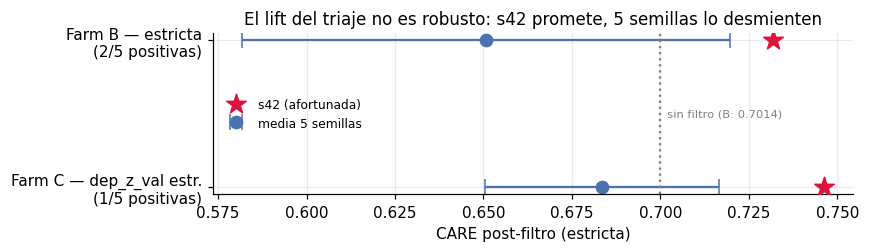

Farm B — estricta: s42=0.7318 pero 5-seed 0.6508+-0.069 (positivas 2/5).
Farm C — dep_z_val estr.: s42=0.7462 pero 5-seed 0.6835+-0.033 (positivas 1/5).


In [7]:
import matplotlib.pyplot as plt
multiseed = {
    "Farm B — estricta":        {"s42": 0.7318, "media": 0.6508, "sd": 0.069, "positivas": "2/5"},
    "Farm C — dep_z_val estr.": {"s42": 0.7462, "media": 0.6835, "sd": 0.033, "positivas": "1/5"},
}
fig, ax = plt.subplots(figsize=(8, 2.4))
y = np.arange(len(multiseed))
for i, (name, d) in enumerate(multiseed.items()):
    ax.errorbar(d["media"], i, xerr=d["sd"], fmt="o", color="#4C72B0", capsize=5, ms=8, label="media 5 semillas" if i == 0 else None)
    ax.scatter(d["s42"], i, color="crimson", marker="*", s=180, zorder=5, label="s42 (afortunada)" if i == 0 else None)
ax.set_yticks(y); ax.set_yticklabels([f"{n}\n({d['positivas']} positivas)" for n, d in multiseed.items()])
ax.invert_yaxis()   # B arriba, en el orden en que se lee la tabla y se cita en las conclusiones
ax.axvline(0.70, ls=":", color="gray"); ax.set_xlabel("CARE post-filtro (estricta)")

ax.text(0.70, 0.5, "  sin filtro (B: 0.7014)", transform=ax.get_xaxis_transform(),
        ha="left", va="center", fontsize=7.5, color="gray")
ax.set_title("El lift del triaje no es robusto: s42 promete, 5 semillas lo desmienten")
ax.legend(fontsize=8, loc="center left", framealpha=0.9); plt.tight_layout(); plt.show()

for name, d in multiseed.items():
    print(f"{name}: s42={d['s42']:.4f} pero 5-seed {d['media']:.4f}+-{d['sd']:.3f} (positivas {d['positivas']}).")

## 4. Conclusiones y limitaciones

1. **La evidencia *label-free* reproduce la interpretabilidad de los notebooks de explicabilidad**
   desde una sola función. El margen, el contrafactual y los gradientes integrados distinguen un
   fallo de canal único (ev66) de una deriva **relacional** (ev11) que un detector de umbral no
   vería.
2. **El diagnóstico lo deciden reglas calibradas y el modelo de lenguaje solo narra**, con el mismo
   diseño que el Agente 2. El experimento de control lo respalda, porque dejado decidir, el modelo
   local sobre-escala los casos ambiguos, así que el número que se declara es siempre el del
   mecanismo determinista.
3. **La categorización no mejora el CARE de forma robusta.** El efecto de una semilla en el parque B
   (+0.0305) se desvanece a cinco (0.6508 ± 0.069, positivo en 2 de 5), y en el parque C ocurre lo
   mismo (0.7462 a la semilla de referencia y 0.6835 ± 0.033 a cinco, positivo en 1 de 5).
4. **Es un replanteamiento, no un fracaso.** Lo robusto no es el filtro sino **la decisión de
   escalar los precursores fuertes**, que no depende de la semilla y es justo lo que necesita el
   planificador del notebook 6. Por eso el prototipo despliega el detector campeón **sin** el filtro
   de categorización, y el agente queda como una **capa de decisión interpretable**.

**Limitaciones.**

1. El triaje *label-free* no puede rescatar anomalías débiles y transitorias, porque una anomalía
   real de bajo margen es indistinguible de una falsa alarma pasajera. Por eso la variante
   `principal` incluso baja el CARE, al descartar una de ellas.
2. La evaluación multi-semilla exige reentrenar el detector por cada semilla, con el coste que eso
   supone.
3. Los umbrales de la taxonomía se calibraron en los notebooks 1 a 4 y no se reajustan aquí, para
   evitar el *cherry-picking*.